# Tasa de paro

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"                 # carpeta en research/temas/
GRAFICA_ID = "tasa-paro"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Tasa de paro"  # `titulo` de la gráfica en config.json
DESDE = 1976                    # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"         # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = '% de la población activa'  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"              # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1               # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None               # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None               # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de la población activa (las personas que trabajan o buscan empleo) que está en paro: no tiene empleo, lo busca activamente y está disponible para trabajar, con la definición de la Organización Internacional del Trabajo (OIT). Es la cifra más usada para comparar el desempleo entre países.

**Cómo se lee.** Es la media anual de la tasa mensual o trimestral de las encuestas de población activa. Un valor de 10 significa que de cada cien personas activas, diez están en paro.

**Limitaciones.**
- La tasa de paro no recoge a quienes han dejado de buscar empleo ni al empleo a tiempo parcial no deseado.
- Cada fuente usa un rango de edad algo distinto (15 años o más en la OCDE; de 15 a 74 años en Eurostat; 16 años o más en la EPA del INE).
- La Encuesta de Población Activa (EPA) tuvo cambios metodológicos en 2001 y 2005; las series enlazadas de la OCDE y de Eurostat los recogen, y las notas indican las diferencias con la EPA.
- **Vista por comunidades** (METODOLOGIA §2.7): la tasa de paro anual de la EPA del INE en cada comunidad y ciudad autónoma, con el total nacional de la misma tabla como España (16 años o más). En las comunidades pequeñas y en Ceuta y Melilla la muestra es menor y el error de muestreo, mayor: las diferencias pequeñas entre comunidades o entre años pueden no ser significativas.

## 2. Descarga

- **España, EE. UU., Canadá y OCDE:** OCDE, Encuestas de población activa (`OECD.SDD.TPS,DSD_LFS@DF_IALFS_UNE_M`, versión 1.0): tasa de paro (`UNE_LF_M`), total, 15 años o más, frecuencia anual (`A`).
- **UE-27:** Eurostat `une_rt_a`: tasa de paro (`PC_ACT`, % de la población activa), de 15 a 74 años, ambos sexos, UE-27.
- **Solo para las notas:** INE, EPA, serie `EPA86913` (tasa de paro, ambos sexos, total nacional), media de los cuatro trimestres.
- **Vista por comunidades:** INE, EPA, tabla 74999 (*Tasas de paro por distintos grupos de edad, sexo y comunidad autónoma*, anual desde 2006): tasa de paro, ambos sexos, todas las edades, del total nacional y de cada comunidad y ciudad autónoma. Los códigos de serie se buscan en el código por su nombre en la tabla (servicio `SERIES_TABLA` de la API del INE), no se copian a mano. Solo para las notas, la tabla trimestral 65334 (las mismas tasas por trimestre, desde 2002): la media de sus cuatro trimestres no es exactamente el dato anual (que divide los parados medios del año entre los activos medios) y no se empalma con la tabla anual.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos

from datetime import date

import requests

from lib import eurostat, ine, oecd
from lib._http import pedir
from lib.ccaa import NOMBRES_CCAA
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, construir_vista_ccaa, write_grafica_data

HOY = date.today().isoformat()
AREAS_OCDE = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde"}
DATAFLOW_UNE = "OECD.SDD.TPS,DSD_LFS@DF_IALFS_UNE_M,1.0"
# Dimensiones: país . medida . unidad . transformación . ajuste . sexo . edad . actividad . frecuencia
CLAVE_UNE = "{AREA}.UNE_LF_M.PT_LF_SUB._Z.N._T.Y_GE15._Z.A"

oc, fuentes_oc = oecd.get(DATAFLOW_UNE, CLAVE_UNE, areas=AREAS_OCDE, desde=DESDE)
eu, fuentes_eu = eurostat.get(
    "une_rt_a", {"age": "Y15-74", "sex": "T", "unit": "PC_ACT"}, geos={"EU27_2020": "ue27"}, desde=DESDE
)
epa, _ = ine.get({"EPA86913": "espana"}, agregacion="media", desde=DESDE)
print(oc.groupby("serie")["periodo"].agg(["min", "max"]))
print(eu.groupby("serie")["periodo"].agg(["min", "max"]))

# Vista por comunidades
TABLA_ANUAL = 74999  # EPA: tasas de paro por grupo de edad, sexo y comunidad autónoma (anual)
TABLA_TRIM = 65334  # las mismas tasas por trimestre (solo para las notas)
# Nombre de la zona en las series del INE → clave de la serie (ISO 3166-2:ES)
INE_A_ISO = {
    "Total Nacional": "espana", "Andalucía": "ES-AN", "Aragón": "ES-AR", "Asturias, Principado de": "ES-AS",
    "Balears, Illes": "ES-IB", "Canarias": "ES-CN", "Cantabria": "ES-CB", "Castilla y León": "ES-CL",
    "Castilla - La Mancha": "ES-CM", "Cataluña": "ES-CT", "Comunitat Valenciana": "ES-VC", "Extremadura": "ES-EX",
    "Galicia": "ES-GA", "Madrid, Comunidad de": "ES-MD", "Murcia, Región de": "ES-MC",
    "Navarra, Comunidad Foral de": "ES-NC", "País Vasco": "ES-PV", "Rioja, La": "ES-RI", "Ceuta": "ES-CE",
    "Melilla": "ES-ML",
}
assert set(INE_A_ISO.values()) == {"espana", *NOMBRES_CCAA}, "faltan comunidades"


def series_tabla(tabla, edad):
    """Códigos de las series «Tasa de paro de la población. Ambos sexos. <zona>. <edad>» de una tabla del INE."""
    r = pedir(
        requests.Session(), f"https://servicios.ine.es/wstempus/js/ES/SERIES_TABLA/{tabla}", {},
        error_cls=ine.IneError, etiqueta=f"tabla {tabla}", mensaje=lambda r: r.text[:200],
    )
    codigos = {}
    for s in r.json():
        partes = [p.strip() for p in s["Nombre"].split(".") if p.strip()]
        zona = [p for p in partes if p in INE_A_ISO]
        if {"Tasa de paro de la población", "Ambos sexos", edad} <= set(partes) and len(zona) == 1:
            codigos[s["COD"]] = INE_A_ISO[zona[0]]
    assert sorted(codigos.values()) == sorted(INE_A_ISO.values()), f"tabla {tabla}: no están todas las zonas"
    return codigos


SERIES_CCAA = series_tabla(TABLA_ANUAL, "Todas las edades")
df_ccaa, fuentes_ccaa_ine = ine.get(SERIES_CCAA, desde=DESDE)
trimestral_ccaa, _ = ine.get(series_tabla(TABLA_TRIM, "Total"), agregacion="media", desde=DESDE)  # solo para las notas
print(df_ccaa.groupby("serie")["periodo"].agg(["min", "max"]).T)

         min   max
serie             
canada  1976  2025
eeuu    1976  2024
espana  1987  2025
ocde    2005  2024
        min   max
serie            
ue27   2009  2025


serie  ES-AN  ES-AR  ES-AS  ES-CB  ES-CE  ES-CL  ES-CM  ES-CN  ES-CT  ES-EX  \
min     2006   2006   2006   2006   2006   2006   2006   2006   2006   2006   
max     2025   2025   2025   2025   2025   2025   2025   2025   2025   2025   

serie  ES-GA  ES-IB  ES-MC  ES-MD  ES-ML  ES-NC  ES-PV  ES-RI  ES-VC  espana  
min     2006   2006   2006   2006   2006   2006   2006   2006   2006    2006  
max     2025   2025   2025   2025   2025   2025   2025   2025   2025    2025  


## 3. Transformación

1. Las series de la OCDE (España, EE. UU., Canadá, OCDE) y de Eurostat (UE-27) se usan tal como las publican las fuentes: son tasas, sin deflactor ni conversión.
2. **Diferencia de edades:** la OCDE usa 15 años o más y Eurostat de 15 a 74 años; para la UE-27 la OCDE no publica el agregado en este dataflow y se usa Eurostat. Las notas lo recogen.
3. **Comparación con la EPA:** la media anual de la tasa trimestral del INE (16 años o más) frente a la de la OCDE para España.
4. **Vista por comunidades:** el dato anual del INE tal como lo publica, con el total nacional de la misma tabla como España; para las notas, la diferencia con la media de los cuatro trimestres de la tabla trimestral.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


df = pd.concat([oc, eu], ignore_index=True)
fuentes = [*fuentes_oc, *fuentes_eu]

esp = oc[oc["serie"] == "espana"].set_index("periodo")["valor"]
ine_esp = epa.set_index("periodo")["valor"]
comunes = sorted(set(esp.index) & set(ine_esp.index))
dif = (esp[comunes] - ine_esp[comunes]).abs()
NOTAS = [
    "España, EE. UU., Canadá y OCDE: OCDE, Encuestas de población activa (DSD_LFS@DF_IALFS_UNE_M): tasa de paro de la "
    "población de 15 años o más, media anual, definición armonizada de la OIT.",
    "UE-27: Eurostat (une_rt_a), población de 15 a 74 años, ambos sexos, agregado de composición actual (EU27_2020). "
    "La OCDE usa 15 años o más y Eurostat de 15 a 74 años, por lo que las dos series no son estrictamente comparables.",
    f"Comparación de España con la EPA del INE (serie EPA86913, población de 16 años o más, media de los cuatro "
    f"trimestres): en los {len(comunes)} años que tienen en común ({comunes[0]}-{comunes[-1]}), la diferencia máxima "
    f"entre las dos fuentes es de {es(dif.max(), 2)} puntos, en {int(dif.idxmax())}.",
    "Rupturas de serie de la EPA: cambio de la definición de parado en 2001 y renovación del cuestionario y de la "
    "metodología de la encuesta en 2005; las series de la OCDE y de Eurostat las enlazan.",
]

# Vista por comunidades (METODOLOGIA §2.7)
assert df_ccaa["valor"].between(0, 60).all(), "porcentaje fuera de rango (comunidades)"
fuentes_ccaa = [
    FuenteMeta(f.serie, f.organismo, f"EPA, tabla {TABLA_ANUAL}: serie {f.dataset_codigo} (anual)", f.url, f.fecha_consulta)
    for f in fuentes_ccaa_ine
]
a = df_ccaa.set_index(["serie", "periodo"])["valor"]
b = trimestral_ccaa.set_index(["serie", "periodo"])["valor"]
dif_trim = (a[a.index.intersection(b.index)] - b[a.index.intersection(b.index)]).abs()
DIF_MAX, (ZONA_MAX, ANIO_MAX) = dif_trim.max(), dif_trim.idxmax()
NOMBRE_MAX = "el total de España" if ZONA_MAX == "espana" else NOMBRES_CCAA[ZONA_MAX]
assert DIF_MAX < 0.5, "la media de los trimestres se aleja demasiado del dato anual: revisar las series"
PRIMERO, PRIMERO_TRIM = int(df_ccaa["periodo"].min()), int(trimestral_ccaa["periodo"].min())
NOTAS_CCAA = [
    f"INE, Encuesta de Población Activa (tabla {TABLA_ANUAL}): tasa de paro anual de la población de 16 años o más, "
    f"ambos sexos, de cada comunidad y ciudad autónoma; España es el total nacional de la misma tabla (en la vista "
    f"España, la serie de la OCDE, de 15 años o más). La tabla anual empieza en {PRIMERO}.",
    f"La tabla trimestral del INE (tabla {TABLA_TRIM}) empieza en {PRIMERO_TRIM}; la media de sus cuatro trimestres "
    f"difiere del dato anual como mucho {es(dif_trim['espana'].max(), 2)} puntos en el total de España y "
    f"{es(DIF_MAX, 2)} en {NOMBRE_MAX} ({int(ANIO_MAX)}), y no se empalma con la tabla anual.",
    "La EPA es una encuesta: en las comunidades pequeñas y en Ceuta y Melilla el error de muestreo es mayor y las "
    "diferencias pequeñas entre comunidades o entre años pueden no ser significativas.",
]
for n in [*NOTAS, *NOTAS_CCAA]:
    print("-", n)
vista_ccaa = construir_vista_ccaa(df_ccaa, fuentes_ccaa, unidad=UNIDAD, notas=NOTAS_CCAA, desde=DESDE)

- España, EE. UU., Canadá y OCDE: OCDE, Encuestas de población activa (DSD_LFS@DF_IALFS_UNE_M): tasa de paro de la población de 15 años o más, media anual, definición armonizada de la OIT.
- UE-27: Eurostat (une_rt_a), población de 15 a 74 años, ambos sexos, agregado de composición actual (EU27_2020). La OCDE usa 15 años o más y Eurostat de 15 a 74 años, por lo que las dos series no son estrictamente comparables.
- Comparación de España con la EPA del INE (serie EPA86913, población de 16 años o más, media de los cuatro trimestres): en los 22 años que tienen en común (2002-2023), la diferencia máxima entre las dos fuentes es de 0,15 puntos, en 2021.
- Rupturas de serie de la EPA: cambio de la definición de parado en 2001 y renovación del cuestionario y de la metodología de la encuesta en 2005; las series de la OCDE y de Eurostat las enlazan.
- INE, Encuesta de Población Activa (tabla 74999): tasa de paro anual de la población de 16 años o más, ambos sexos, de cada comunidad y ciudad aut

## 4. Visualización

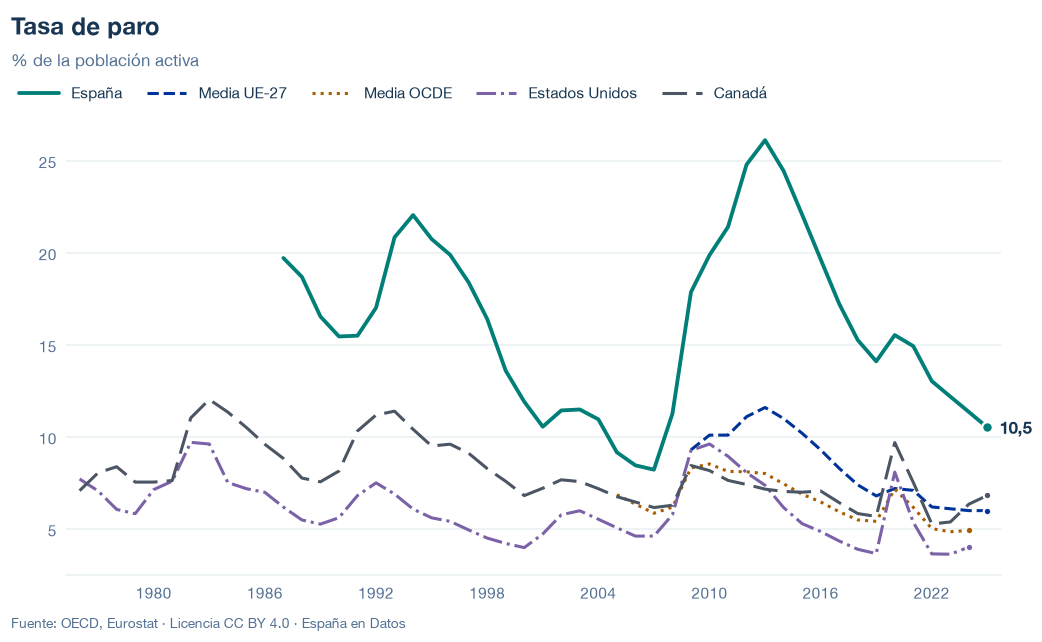

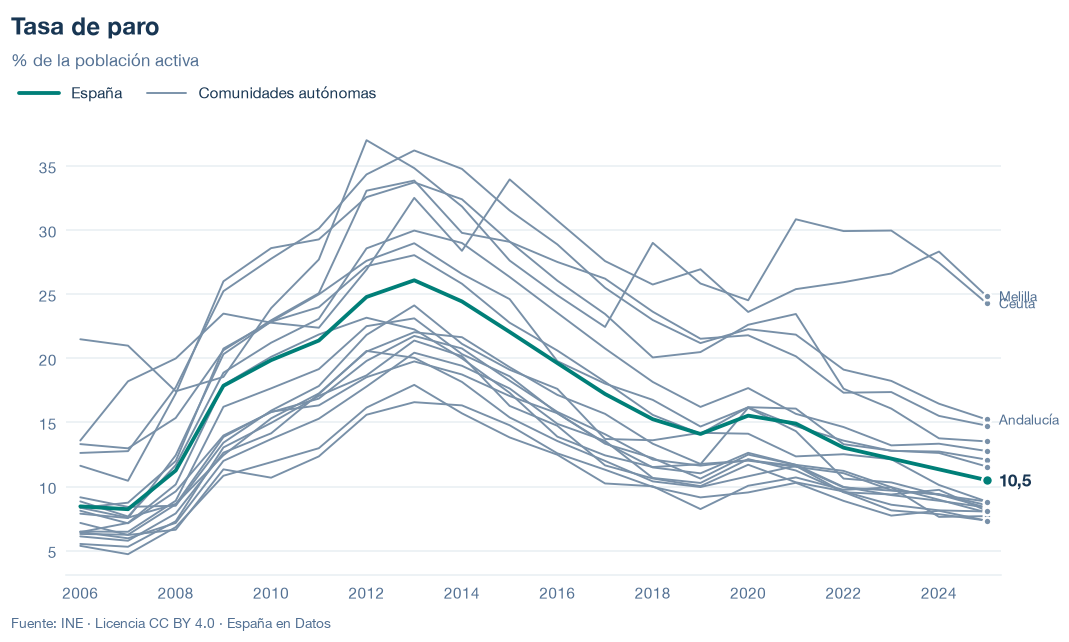

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA, ccaa=vista_ccaa,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)
estilos.mostrar(estilos.figura_ccaa(datos, titulo=TITULO))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA, ccaa=vista_ccaa,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/tasa-paro.json y data/tasa-paro.csv


## 6. Fuentes, notas y licencia

- OCDE, Encuestas de población activa: `OECD.SDD.TPS,DSD_LFS@DF_IALFS_UNE_M,1.0` (`UNE_LF_M`, `PT_LF_SUB`, `N`, `_T`, `Y_GE15`, `A`).
- Eurostat, `une_rt_a` (`Y15-74`, `T`, `PC_ACT`).
- INE, EPA, serie `EPA86913` (solo para las notas).
- INE, EPA, tabla 74999 (tasa de paro por comunidad autónoma, anual; un código de serie por comunidad, buscado por su nombre en la tabla) para la vista por comunidades, y tabla 65334 (trimestral; solo para las notas).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.